<a href="https://colab.research.google.com/github/huynhtamtri2006-gif/TH---MACHINE_LEARNING/blob/main/tuan_2/B%C3%80I_T%E1%BA%ACP_3_BU%E1%BB%94I_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
#Đọc và khám phá dữ liệu
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y

print("Kích thước dữ liệu:", df.shape)
print("Tên các lớp:", iris.target_names)

display(df.head(10))

print("\nSố lượng mẫu từng lớp:")
print(df['target'].value_counts())

print("\nKiểm tra dữ liệu thiếu:")
print(df.isnull().sum())

display(df.describe())

Kích thước dữ liệu: (150, 5)
Tên các lớp: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0



Số lượng mẫu từng lớp:
target
0    50
1    50
2    50
Name: count, dtype: int64

Kiểm tra dữ liệu thiếu:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
#Phân chia tập dữ liệu ban đầu
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [4]:
#Chuẩn hóa dữ liệu
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Trước chuẩn hóa:")
print(X_train[:5])

print("\nSau chuẩn hóa:")
print(X_train_scaled[:5])

print("\nMean:")
print(X_train_scaled.mean(axis=0))

print("\nStandard Deviation:")
print(X_train_scaled.std(axis=0))

Trước chuẩn hóa:
[[4.4 2.9 1.4 0.2]
 [4.9 2.5 4.5 1.7]
 [6.8 2.8 4.8 1.4]
 [4.9 3.1 1.5 0.1]
 [5.5 2.5 4.  1.3]]

Sau chuẩn hóa:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Mean:
[-1.20829273e-15 -2.03679666e-15  4.99600361e-16  1.67458640e-15]

Standard Deviation:
[1. 1. 1. 1.]


In [5]:
#Xây dựng mô hình SVM Classification
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

svm_model.fit(X_train_scaled, y_train)

y_pred = svm_model.predict(X_test_scaled)

print("Giá trị thực tế:")
print(y_test)

print("\nGiá trị dự đoán:")
print(y_pred)

Giá trị thực tế:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Giá trị dự đoán:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



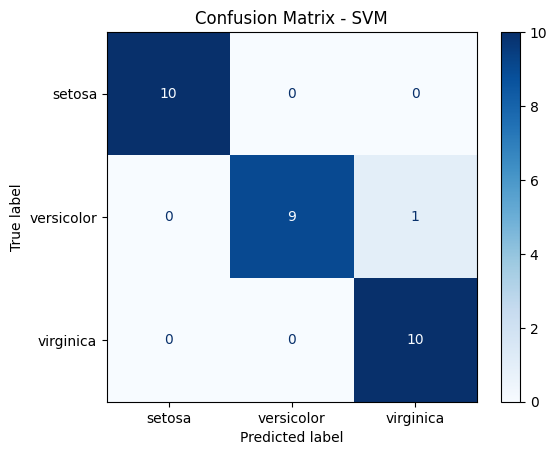

In [6]:
#Đánh giá mô hình ban đầu
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap='Blues'
)

plt.title('Confusion Matrix - SVM')
plt.show()

In [7]:
#Thực nghiệm với nhiều tỷ lệ chia dữ liệu
test_sizes = [0.4, 0.3, 0.2, 0.1]

results = []

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    )

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    results.append({
        'Train (%)': round((1 - test_size) * 100),
        'Test (%)': round(test_size * 100),
        'Train Samples': len(y_train),
        'Test Samples': len(y_test),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        )
    })

df_results = pd.DataFrame(results)

display(df_results.round(4))

,Train (%),Test (%),Train Samples,Test Samples,Accuracy,Precision,Recall,F1-score
0,60,40,90,60,0.9500,0.9507,0.9500,0.9500
1,70,30,105,45,0.9333,0.9345,0.9333,0.9333
2,80,20,120,30,0.9667,0.9697,0.9667,0.9666
3,90,10,135,15,0.9333,0.9444,0.9333,0.9327


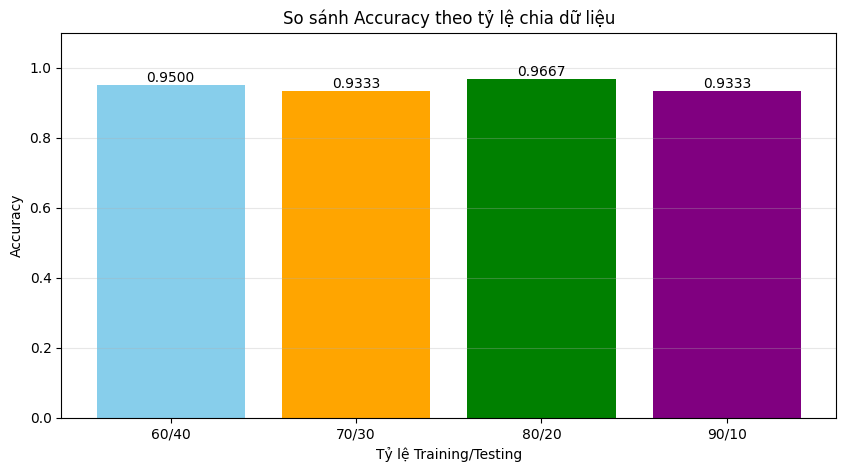

In [8]:
#Vẽ biểu đồ so sánh các tỷ lệ chia
labels = (
    df_results['Train (%)'].astype(str)
    + '/'
    + df_results['Test (%)'].astype(str)
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    labels,
    df_results['Accuracy'],
    color=['skyblue', 'orange', 'green', 'purple']
)

plt.bar_label(bars, fmt='%.4f')

plt.xlabel('Tỷ lệ Training/Testing')
plt.ylabel('Accuracy')
plt.title('So sánh Accuracy theo tỷ lệ chia dữ liệu')
plt.ylim(0, 1.1)
plt.grid(axis='y', alpha=0.3)
plt.show()

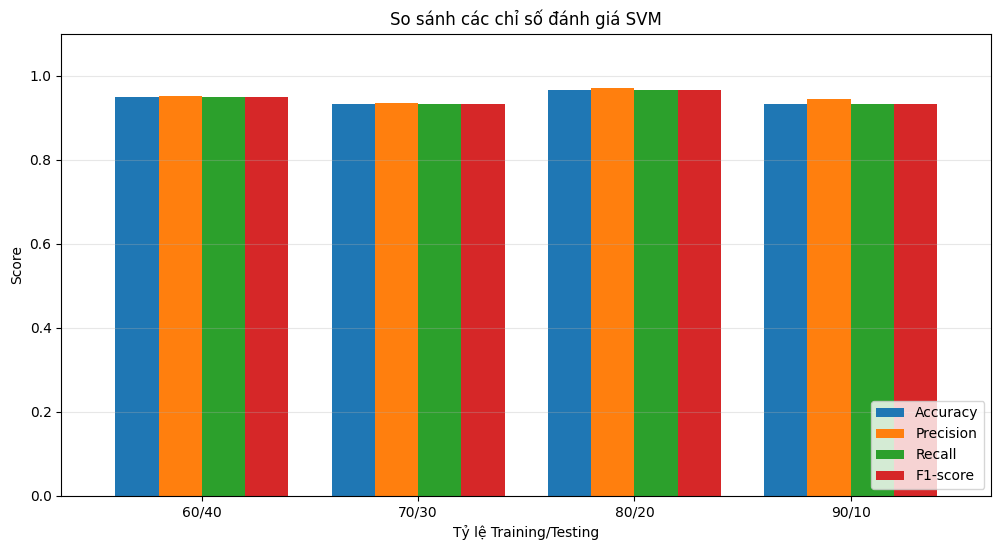

In [9]:
#So sánh tất cả chỉ số đánh giá
df_results[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].set_axis(labels).plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.xlabel('Tỷ lệ Training/Testing')
plt.ylabel('Score')
plt.title('So sánh các chỉ số đánh giá SVM')
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [10]:
#Xác định tỷ lệ chia có kết quả tốt nhất
best_result = df_results.loc[
    df_results['Accuracy'].idxmax()
]

print("Tỷ lệ chia có Accuracy cao nhất:")

print(f"Training: {best_result['Train (%)']:.0f}%")
print(f"Testing: {best_result['Test (%)']:.0f}%")
print(f"Accuracy: {best_result['Accuracy']:.4f}")
print(f"Precision: {best_result['Precision']:.4f}")
print(f"Recall: {best_result['Recall']:.4f}")
print(f"F1-score: {best_result['F1-score']:.4f}")

Tỷ lệ chia có Accuracy cao nhất:
Training: 80%
Testing: 20%
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1-score: 0.9666
